# Flood Susceptibility Mapping and SHAP-Based Interpretation

This code aims to predict flood susceptibility using a machine learning model, with historical flood occurrence as the target variable (y) and five physical factors—elevation, slope, flow accumulation, distance to rivers, and land use/land cover (LULC)—as input features (X). 
SHapley Additive exPlanations (SHAP) is then applied to interpret the contribution of each physical factor to the model's predictions.

### Inspect the Generated Datasets

In [1]:
import rasterio
import os
import numpy as np

data_path = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기"

raster_paths = {
    "DEM": os.path.join(data_path, "DEM_5m_QCmasked.tif"),
    "Slope": os.path.join(data_path, "Slope.tif"),
    "FA": os.path.join(data_path, "Flow Accumulation.tif"),
    "RiverDistance": os.path.join(data_path, "distance_to_water.tif"),
    "LULC": os.path.join(data_path, "LULC_L3_5m_aligned.tif"),
}

for name, path in raster_paths.items():
    print(f"\n===== {name} =====")

    with rasterio.open(path) as src:
        print("EPSG:", src.crs.to_epsg())
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Shape:", src.height, src.width)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)


===== DEM =====
EPSG: 5179
CRS: EPSG:5179
Resolution: (4.9998026000000015, 4.9998076)
Shape: 8976 9732
Bounds: BoundingBox(left=1115170.9713118004, bottom=1666745.8611512, right=1163829.0502150005, top=1711624.1341688)
NoData: -9999.0

===== Slope =====
EPSG: 5179
CRS: EPSG:5179
Resolution: (4.9998026000000015, 4.9998076)
Shape: 8976 9732
Bounds: BoundingBox(left=1115170.9713118004, bottom=1666745.8611512, right=1163829.0502150005, top=1711624.1341688)
NoData: -9999.0

===== FA =====
EPSG: 5179
CRS: EPSG:5179
Resolution: (4.9998026, 4.9998026)
Shape: 8976 9732
Bounds: BoundingBox(left=1115170.9713118004, bottom=1666745.8835912, right=1163829.0502150005, top=1711624.1117288)
NoData: -99999.0

===== RiverDistance =====
EPSG: None
CRS: PROJCS["Korea_2000_Korea_Unified_Coordinate_System",GEOGCS["GCS_Korea_2000",DATUM["Korean_Geodetic_Datum_2002",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6737"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925

### Check LULC separately

In [2]:
with rasterio.open(raster_paths["LULC"]) as src:
    print("EPSG:", src.crs.to_epsg())
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Shape:", src.height, src.width)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)

with rasterio.open(raster_paths["LULC"]) as src:
    arr = src.read(1)
    vals = np.unique(arr)
    print("Unique values:", vals[:100])
    print("Number of Unique values:", len(vals))

EPSG: 5179
CRS: EPSG:5179
Resolution: (4.9998026000000015, 4.9998076)
Shape: 8976 9732
Bounds: BoundingBox(left=1115170.9713118004, bottom=1666745.8611511998, right=1163829.0502150005, top=1711624.1341687997)
NoData: None
Unique values: [-9999.   111.   112.   121.   131.   141.   152.   153.   154.   155.
   161.   162.   163.   211.   212.   221.   222.   231.   241.   251.
   252.   311.   321.   331.   411.   421.   422.   423.   511.   521.
   611.   612.   613.   621.   622.   623.   711.   712.   721.]
Number of Unique values: 39


### Define functions

In [4]:
# Define a function to precisely align other rasters with the reference DEM grid
def align_to_dem(path):
    with rasterio.open(path) as src:
        source = src.read(1).astype("float32")

        # Replace metadata-defined NoData values with NaN.
        if src.nodata is not None:
            source[source == src.nodata] = np.nan

        # Handle NoData values not defined in the metadata.
        source[np.isin(source, [-9999, -99999])] = np.nan

        # Initialize the destination array using the DEM grid dimensions.
        destination = np.full(
            master_shape,
            np.nan,
            dtype="float32"
        )

        # Align the source raster to the reference DEM grid.
        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=master_transform,
            dst_crs=master_crs,
            resampling=Resampling.nearest,
            src_nodata=np.nan,
            dst_nodata=np.nan
        )

    return destination




# Define a function to reshape rasters into 5×5 pixel blocks.
def make_blocks(arr, factor=5):
    h, w = arr.shape

    return (
        arr
        .reshape(
            h // factor,
            factor,
            w // factor,
            factor
        )
        .transpose(0, 2, 1, 3)
    )



### Raster Preprocessing and 25m Grid-Based Feature Extraction for Machine Learning

In [6]:
from rasterio.warp import reproject, Resampling
import pandas as pd
from scipy import stats

# File paths
dem_path = os.path.join(data_path, "DEM_5m_QCmasked.tif")
slope_path = os.path.join(data_path, "Slope.tif")
fa_path = os.path.join(data_path, "Flow Accumulation.tif")
river_path = os.path.join(data_path, "distance_to_water.tif")
lulc_path = os.path.join(data_path, "LULC_L3_5m_aligned.tif")


## 1. Load the DEM as the master reference grid
with rasterio.open(dem_path) as src:
    dem = src.read(1).astype("float32")
    master_transform = src.transform
    master_crs = src.crs
    master_shape = (src.height, src.width)
    dem_nodata = src.nodata

print("Master grid shape:", master_shape)
print("Master CRS:", master_crs)
print("Master transform:", master_transform)

# Replace NoData values with NaN
if dem_nodata is not None:
    dem[dem == dem_nodata] = np.nan



## 2. Align all raster datasets to the reference DEM grid
print("\nAligning Slope...")
slope = align_to_dem(slope_path)

print("Aligning Flow Accumulation...")
fa = align_to_dem(fa_path)

print("Aligning River Distance...")
river = align_to_dem(river_path)

print("Aligning LULC...")
lulc = align_to_dem(lulc_path)

print("\nAlignment complete.")

print("DEM:", dem.shape)
print("Slope:", slope.shape)
print("FA:", fa.shape)
print("River:", river.shape)
print("LULC:", lulc.shape)



## 3. Trim excess rows and columns to ensure divisibility by 5
# Trim excess rows and columns to make the dimensions divisible by 5, allowing aggregation of 5×5 pixels into a single 25m grid cell.
factor = 5
h, w = master_shape

new_h = (h // factor) * factor
new_w = (w // factor) * factor

print("\nOriginal:", h, w)
print("Trimmed :", new_h, new_w)

dem = dem[:new_h, :new_w]
slope = slope[:new_h, :new_w]
fa = fa[:new_h, :new_w]
river = river[:new_h, :new_w]
lulc = lulc[:new_h, :new_w]



## 4. Aggregate raster values from 5m to approximately 25m
# DEM: Calculate the mean elevation within each block.
dem_b = make_blocks(dem)
slope_b = make_blocks(slope)
fa_b = make_blocks(fa)
river_b = make_blocks(river)
lulc_b = make_blocks(lulc)
print("\nBlock shape:", dem_b.shape)

dem_25 = np.nanmean(dem_b, axis=(2, 3))

# Slope: Calculate the mean slope within each block
slope_25 = np.nanmean(slope_b, axis=(2, 3))

# Flow Accumulation: Extract the maximum value within each block
fa_25_raw = np.nanmax(fa_b, axis=(2, 3))

# Apply log1p transformation after maximum aggregation
fa_25_log = np.log1p(fa_25_raw)

# River Distance: Extract the minimum distance within each block
river_25 = np.nanmin(river_b, axis=(2, 3))



## 5. Aggregate LULC using the mode (most frequent class)
# Flatten each 5×5 block into an array of 25 pixels
lulc_flat = lulc_b.reshape(lulc_b.shape[0], lulc_b.shape[1], 25)

# Calculate the mode while ignoring NaN values.
lulc_25 = stats.mode(
    lulc_flat,
    axis=2,
    nan_policy="omit",
    keepdims=False
).mode

print("\n25m aggregation complete.")



## 6. Calculate the center coordinates of each 25m grid cell
rows, cols = dem_25.shape

# Retrieve the original DEM pixel resolution (approximately 5m).
# Use abs() because the Y resolution is negative for north-up rasters.
xres = master_transform.a # a: Pixel width (X resolution)
yres = abs(master_transform.e) # e: Pixel height (negative for north-up rasters)

# Calculate the dimensions of each aggregated grid cell.
# Each 25m grid cell consists of 5×5 original 5m pixels.
cell_x = xres * factor
cell_y = yres * factor

# Retrieve the upper-left corner coordinates of the DEM.
left = master_transform.c # c: X coordinate of the upper-left corner
top = master_transform.f # f: Y coordinate of the upper-left corner

# Calculate the center coordinates of each 25m grid cell.
# np.arange() generates sequential row/column indices starting from 0.
# Adding 0.5 shifts the coordinates from the cell corner to its center.
x_centers = (
    left
    + (np.arange(cols) + 0.5) * cell_x
)

# Subtract because Y coordinates decrease toward the south.
y_centers = (
    top
    - (np.arange(rows) + 0.5) * cell_y
)

# Create 2D coordinate arrays for all grid cell centers.
# xx and yy have the same shape as dem_25 (1795, 1946).
xx, yy = np.meshgrid(
    x_centers,
    y_centers
)

# Verify the coordinate ranges.
print("\n25m grid coordinate range:")
print("coord_x:", xx.min(), "~", xx.max())
print("coord_y:", yy.min(), "~", yy.max())



## 7. Create a DataFrame containing ML input features
df_25m = pd.DataFrame({

    "row": np.repeat(
        np.arange(rows),
        cols
    ),

    "col": np.tile(
        np.arange(cols),
        rows
    ),

    # Spatial coordinates in EPSG:5179.
    # Use distinct names to avoid confusion with the ML target variable (y)
    "coord_x": xx.ravel(),
    "coord_y": yy.ravel(),

    "DEM": dem_25.ravel(),

    "Slope": slope_25.ravel(),

    # Preserve the original aggregated FA values
    "FA_raw": fa_25_raw.ravel(),

    # Use log-transformed FA values as an ML input feature
    "FA_log1p": fa_25_log.ravel(),

    "RiverDistance": river_25.ravel(),

    "LULC": lulc_25.ravel()
})



Master grid shape: (8976, 9732)
Master CRS: EPSG:5179
Master transform: | 5.00, 0.00, 1115170.97|
| 0.00,-5.00, 1711624.13|
| 0.00, 0.00, 1.00|

Aligning Slope...
Aligning Flow Accumulation...
Aligning River Distance...
Aligning LULC...

Alignment complete.
DEM: (8976, 9732)
Slope: (8976, 9732)
FA: (8976, 9732)
River: (8976, 9732)
LULC: (8976, 9732)

Original: 8976 9732
Trimmed : 8975 9730

Block shape: (1795, 1946, 5, 5)


C:\Users\nayou\AppData\Local\Temp\ipykernel_32404\1071434018.py:82: RuntimeWarning: Mean of empty slice
  dem_25 = np.nanmean(dem_b, axis=(2, 3))
C:\Users\nayou\AppData\Local\Temp\ipykernel_32404\1071434018.py:85: RuntimeWarning: Mean of empty slice
  slope_25 = np.nanmean(slope_b, axis=(2, 3))
C:\Users\nayou\AppData\Local\Temp\ipykernel_32404\1071434018.py:88: RuntimeWarning: All-NaN slice encountered
  fa_25_raw = np.nanmax(fa_b, axis=(2, 3))
C:\Users\nayou\AppData\Local\Temp\ipykernel_32404\1071434018.py:103: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  lulc_25 = stats.mode(



25m aggregation complete.

25m grid coordinate range:
coord_x: 1115183.4708183005 ~ 1163806.5511033004
coord_y: 1666763.3604778 ~ 1711611.6346498


### Inspect the DataFrame containing the ML input features (X).

In [7]:
print("\nDataFrame shape:")
print(df_25m.shape)

print("\nPreview:")
print(df_25m.head())

print("\nMissing values:")
print(df_25m.isna().sum())

print("\nLULC classes:")
print(
    np.sort(
        df_25m["LULC"]
        .dropna()
        .unique()
    )
)

print("\nCoordinate check:")
print(
    df_25m[
        ["coord_x", "coord_y"]
    ].agg(["min", "max"])
)

print(df_25m[
    ["DEM", "Slope", "FA_raw", "FA_log1p", "RiverDistance"]
].describe())


DataFrame shape:
(3493070, 10)

Preview:
   row  col       coord_x       coord_y  DEM  Slope  FA_raw  FA_log1p  \
0    0    0  1.115183e+06  1.711612e+06  NaN    NaN     NaN       NaN   
1    0    1  1.115208e+06  1.711612e+06  NaN    NaN     NaN       NaN   
2    0    2  1.115233e+06  1.711612e+06  NaN    NaN     NaN       NaN   
3    0    3  1.115258e+06  1.711612e+06  NaN    NaN     NaN       NaN   
4    0    4  1.115283e+06  1.711612e+06  NaN    NaN     NaN       NaN   

   RiverDistance  LULC  
0          925.0   NaN  
1          900.0   NaN  
2          875.0   NaN  
3          850.0   NaN  
4          825.0   NaN  

Missing values:
row                    0
col                    0
coord_x                0
coord_y                0
DEM              1910037
Slope            1909611
FA_raw           1910037
FA_log1p         1910037
RiverDistance          0
LULC             1639001
dtype: int64

LULC classes:
[111. 112. 121. 131. 141. 152. 153. 154. 155. 161. 162. 163. 211. 212.
 22

In [ ]:
# Select valid 25m grid cells with no missing values in any ML input feature (X).
valid = (
    df_25m["DEM"].notna()
    & df_25m["Slope"].notna()
    & df_25m["FA_log1p"].notna()
    & df_25m["RiverDistance"].notna()
    & df_25m["LULC"].notna()
)

df_valid = df_25m.loc[valid].copy()

# Check the number of total, valid, and excluded grid cells.
print("Total 25m grid cells:", len(df_25m))
print("Valid grid cells:", len(df_valid))
print("Excluded grid cells:", len(df_25m) - len(df_valid))

# Display descriptive statistics for continuous input features.
print("\nDescriptive statistics:")
print(
    df_valid[
        ["DEM", "Slope", "FA_raw", "FA_log1p", "RiverDistance"]
    ].describe()
)

# Check the number of unique LULC classes.
print("\nNumber of unique LULC classes:")
print(df_valid["LULC"].nunique())

# Display the frequency distribution of LULC classes.
print("\nLULC class frequencies:")
print(
    df_valid["LULC"]
    .value_counts()
    .sort_index()
)


Total 25m grid cells: 3493070
Valid grid cells: 1561205
Excluded grid cells: 1931865

Descriptive statistics:
                DEM         Slope        FA_raw      FA_log1p  RiverDistance
count  1.561205e+06  1.561205e+06  1.561205e+06  1.561205e+06   1.561205e+06
mean   9.827824e+01  1.086877e+01  1.273484e+05  7.998643e+00   6.401075e+02
std    1.277950e+02  1.168021e+01  1.498096e+06  2.151589e+00   6.485392e+02
min   -5.000000e+00  0.000000e+00  2.499803e+01  3.258021e+00   0.000000e+00
25%    4.697800e+00  8.436680e-02  5.679814e+02  6.343848e+00   1.786757e+02
50%    4.396554e+01  6.282290e+00  2.226863e+03  7.708798e+00   4.598369e+02
75%    1.494019e+02  2.009414e+01  9.915604e+03  9.201966e+00   8.761564e+02
max    7.930842e+02  6.836720e+01  1.167270e+08  1.857535e+01   4.873695e+03

Number of unique LULC classes:
38

LULC class frequencies:
LULC
111.0     16663
112.0     12696
121.0     25260
131.0     27894
141.0      5749
152.0     13689
153.0      4745
154.0    249858
155.

In [12]:
# Assess monotonic relationships among continuous predictors and identify potential multicollinearity and feature redundancy.
corr_vars = ["DEM", "Slope", "FA_log1p", "RiverDistance"]

corr_spearman = df_valid[corr_vars].corr(method="spearman")

print("Spearman correlation:")
print(corr_spearman.round(3))

Spearman correlation:
                 DEM  Slope  FA_log1p  RiverDistance
DEM            1.000  0.828    -0.445          0.089
Slope          0.828  1.000    -0.500          0.084
FA_log1p      -0.445 -0.500     1.000         -0.041
RiverDistance  0.089  0.084    -0.041          1.000


### Load historical flood inundation data for the ML target variable (y).

In [11]:
import geopandas as gpd

gdf_5179_path = os.path.join(data_path, "침수흔적도", "Flood_history_Busan_5179.gpkg")

# Open flood inundation file
gdf_5179 = gpd.read_file(gdf_5179_path)

print("Flood CRS:", gdf_5179.crs)
print("Flood bounds:", gdf_5179.total_bounds)

print("\nDEM bounds:")
with rasterio.open(dem_path) as src:
    print(src.bounds)

Flood CRS: EPSG:5179
Flood bounds: [1119538.55230129 1670498.13090162 1162574.09410177 1709823.00470117]

DEM bounds:
BoundingBox(left=1115170.9713118004, bottom=1666745.8611512, right=1163829.0502150005, top=1711624.1341688)


### Rasterize Historical Flood Inundation Data and Generate 25m Flood Labels

In [13]:
from rasterio.features import rasterize

# 1. Retrieve the reference DEM grid information
with rasterio.open(dem_path) as src:
    master_shape = (src.height, src.width)
    master_transform = src.transform
    master_crs = src.crs

print("Master grid:", master_shape)
print("Flood CRS:", gdf_5179.crs)



# 2. Rasterize historical flood polygons from all years into a single binary "ever-flooded" mask
shapes = (
    (geom, 1) # (geometry, pixel value): 1 indicates historical flooding
    for geom in gdf_5179.geometry
    if geom is not None and not geom.is_empty
)

flood_5m = rasterize(
    shapes=shapes,
    out_shape=master_shape,
    transform=master_transform,
    fill=0,
    default_value=1,
    dtype="uint8",
    all_touched=False
)

print("5m flooded pixels:", flood_5m.sum())



# 3. Trim excess rows and columns to ensure divisibility by 5, consistent with the previous raster preprocessing
factor = 5

h_trim = (master_shape[0] // factor) * factor
w_trim = (master_shape[1] // factor) * factor

flood_trim = flood_5m[:h_trim, :w_trim]



# 4. Reshape the 5m flood mask into 5×5 pixel blocks corresponding to approximately 25m grid cells
flood_blocks = (
    flood_trim
    .reshape(h_trim // factor, factor,
             w_trim // factor, factor)
    .transpose(0, 2, 1, 3)
)

# Count flooded 5m pixels within each 25m grid cell.
flood_count_25 = flood_blocks.sum(axis=(2, 3))

# Calculate the approximate flood overlap ratio for each grid cell.
overlap_ratio_25 = flood_count_25 / 25.0

print("25m overlap ratio shape:", overlap_ratio_25.shape)



# 5. Assign flood overlap ratios to the 25m grid DataFrames
df_25m["flood_overlap_ratio"] = overlap_ratio_25.ravel()

# Use row and column indices to match overlap ratios with the corresponding valid grid cells
df_valid["flood_overlap_ratio"] = overlap_ratio_25[
    df_valid["row"].to_numpy(),
    df_valid["col"].to_numpy()
]



# 6. Generate the binary ML target variable (y)
# >= 20% overlap : 1 (Flooded)
# = 0% overlap   : 0 (Not flooded)
# 0% < overlap < 20% : -1 (Excluded from training)
ratio = df_valid["flood_overlap_ratio"].to_numpy()

df_valid["y"] = np.select(
    [
        ratio >= 0.20,
        ratio == 0
    ],
    [
        1,
        0
    ],
    default=-1
).astype("int8")




# 7. Inspect the flood overlap ratios and target distribution.
print("\nFlood overlap ratio statistics:")
print(df_valid["flood_overlap_ratio"].describe())

print("\nTarget class counts:")
print(df_valid["y"].value_counts().sort_index())

print("\nTarget class proportions:")
print(
    df_valid["y"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

print("\nTarget class definitions:")
print("-1 = Partial overlap (<20%), excluded from training")
print(" 0 = No historical flood overlap")
print(" 1 = Historical flood overlap (>=20%)")


Master grid: (8976, 9732)
Flood CRS: EPSG:5179
5m flooded pixels: 506517
25m overlap ratio shape: (1795, 1946)

Flood overlap ratio statistics:
count    1.561205e+06
mean     1.297759e-02
std      1.084923e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e+00
Name: flood_overlap_ratio, dtype: float64

Target class counts:
y
-1       2173
 0    1535654
 1      23378
Name: count, dtype: int64

Target class proportions:
y
-1    0.0014
 0    0.9836
 1    0.0150
Name: proportion, dtype: float64

Target class definitions:
-1 = Partial overlap (<20%), excluded from training
 0 = No historical flood overlap
 1 = Historical flood overlap (>=20%)


In [14]:
# Verify the total historical flood extent by merging overlapping polygons across all years
flood_union = gdf_5179.geometry.union_all()

# Convert the union area from m² to km².
flood_area_km2 = flood_union.area / 1_000_000

print(f"Total historical flood extent (union): {flood_area_km2:.2f} km²")

Total historical flood extent (union): 12.66 km²


### Filter 25m Grid Cells Within the Busan Administrative Boundary

In [15]:
import geopandas as gpd
from rasterio.features import rasterize

# 1. Load Busan administrative dong boundaries
adm_path = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\데이터 수집\BND_ADM_DONG_PG\Busan_ADM_DONG_2025.shp"
adm = gpd.read_file(adm_path)
print("Original CRS:", adm.crs)
print("Original bounds:", adm.total_bounds)

adm_5179 = adm.to_crs(epsg=5179)
print("\nReprojected CRS:", adm_5179.crs)
print("Reprojected bounds:", adm_5179.total_bounds)



# 2. Rasterize Busan administrative boundaries onto the reference DEM 5m grid
# Create a binary mask where pixels inside Busan's administrative boundaries are 1 and pixels outside are 0
busan_mask_5m = rasterize(
    [(geom, 1) for geom in adm_5179.geometry
     if geom is not None and not geom.is_empty],
    out_shape=master_shape,
    transform=master_transform,
    fill=0,
    default_value=1,
    dtype="uint8",
    all_touched=False
)



# 3. Convert the 5m mask to a 25m mask using the central 5m pixel of each 25m cell
factor = 5

h_trim = (master_shape[0] // factor) * factor
w_trim = (master_shape[1] // factor) * factor
busan_trim = busan_mask_5m[:h_trim, :w_trim]

# Select the central pixel of each 25m grid cell
busan_mask_25m = busan_trim[2::5, 2::5]

print("\n25m Busan mask shape:", busan_mask_25m.shape)



# 4. Identify grid cells within Busan using the row and column indices of df_valid
inside = busan_mask_25m[
    df_valid["row"].to_numpy(),
    df_valid["col"].to_numpy()
].astype(bool)

print("\nTotal valid grid cells:", len(df_valid))
print("Grid cells within Busan:", inside.sum())
print("Grid cells outside Busan:", (~inside).sum())
print(
    "Percentage of grid cells within Busan:",
    round(inside.mean() * 100, 2),
    "%"
)



# 5. Retain only grid cells within Busan
df_busan = df_valid.loc[inside].copy()

analysis_area_km2 = (
    len(df_busan) * 625 / 1_000_000
)

print(
    f"\nAnalysis area within Busan administrative boundaries: "
    f"{analysis_area_km2:.2f} km²"
)



# 6. Verify the spatial extent and target distribution.
print("\nCoordinate ranges:")
print(
    df_busan[
        ["coord_x", "coord_y"]
    ].agg(["min", "max"])
)

print("\nTarget class counts (y):")
print(
    df_busan["y"]
    .value_counts()
    .sort_index()
)


Original CRS: EPSG:5186
Original bounds: [360768.12061041 256004.21866751 409672.12253191 312478.18723816]

Reprojected CRS: EPSG:5179
Reprojected bounds: [1115081.9672 1655365.3378 1164133.5412 1711697.9536]

25m Busan mask shape: (1795, 1946)

Total valid grid cells: 1561205
Grid cells within Busan: 1254019
Grid cells outside Busan: 307186
Percentage of grid cells within Busan: 80.32 %

Analysis area within Busan administrative boundaries: 783.76 km²

Coordinate ranges:
          coord_x       coord_y
min  1.115183e+06  1.666788e+06
max  1.163807e+06  1.711612e+06

Target class counts (y):
y
-1       2128
 0    1228543
 1      23348
Name: count, dtype: int64


## Flood Susceptibility Prediction Using Machine Learning (Random Forest)

### Data Preprocessing and Train-Test Split for Flood Susceptibility Modeling

In [16]:
from sklearn.model_selection import train_test_split

# 1. Prepare data for machine learning
# Exclude partially flooded grid cells (y = -1)
# Exclude water bodies (rivers, lakes, and marine waters)
water_codes = ["711", "712", "721"]

lulc_code = (df_busan["LULC"].astype("Int64").astype(str))

df_ml = df_busan[
    (df_busan["y"].isin([0, 1])) &
    (~lulc_code.isin(water_codes))
].copy()

print("Total ML samples:", len(df_ml))

print("\nTarget label distribution:")
print(df_ml["y"].value_counts().sort_index())

print("\nRemaining water grid cells:")
print(
    df_ml["LULC"]
    .astype("Int64")
    .astype(str)
    .isin(water_codes)
    .sum()
)



# 2. One-hot encode land cover classes
df_ml["LULC"] = (df_ml["LULC"].astype("Int64").astype(str))
lulc_dummies = pd.get_dummies(df_ml["LULC"], prefix="LULC", dtype="uint8")

print("\nLULC one-hot shape:", lulc_dummies.shape)
print("Number of LULC classes:", lulc_dummies.shape[1])



# 3. Define input features (X) and target labels (y)
X_numeric = df_ml[
    [
        "DEM",
        "Slope",
        "FA_log1p",
        "RiverDistance"
    ]
].copy()

X = pd.concat(
    [
        X_numeric.reset_index(drop=True),
        lulc_dummies.reset_index(drop=True)
    ],
    axis=1
)

y = df_ml["y"].reset_index(drop=True)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())



# 4. Split data into training (80%) and test (20%) sets and verify class distributions
#  Preserve class proportions using stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y # Preserve the flooded and non-flooded class proportions in both training and test sets
)

print("\nTrain:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

print("\nTrain y:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(4))

print("\nTest y:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).round(4))

Total ML samples: 1202450

Target label distribution:
y
0    1179572
1      22878
Name: count, dtype: int64

Remaining water grid cells:
0

LULC one-hot shape: (1202450, 35)
Number of LULC classes: 35

X shape: (1202450, 39)
y shape: (1202450,)

X columns:
['DEM', 'Slope', 'FA_log1p', 'RiverDistance', 'LULC_111', 'LULC_112', 'LULC_121', 'LULC_131', 'LULC_141', 'LULC_152', 'LULC_153', 'LULC_154', 'LULC_155', 'LULC_161', 'LULC_162', 'LULC_163', 'LULC_211', 'LULC_212', 'LULC_221', 'LULC_222', 'LULC_231', 'LULC_241', 'LULC_251', 'LULC_252', 'LULC_311', 'LULC_321', 'LULC_331', 'LULC_411', 'LULC_421', 'LULC_422', 'LULC_423', 'LULC_511', 'LULC_521', 'LULC_611', 'LULC_612', 'LULC_613', 'LULC_621', 'LULC_622', 'LULC_623']

Train: (961960, 39) (961960,)
Test : (240490, 39) (240490,)

Train y:
y
0    943658
1     18302
Name: count, dtype: int64
y
0    0.981
1    0.019
Name: proportion, dtype: float64

Test y:
y
0    235914
1      4576
Name: count, dtype: int64
y
0    0.981
1    0.019
Name: propor

### Random Forest Training and Performance Evaluation

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",  # Assign higher weights to the minority (flooded) class
    random_state=42,
    n_jobs=-1,
    max_depth=20,
    min_samples_leaf=5
)

print("Training Random Forest...")
rf.fit(X_train, y_train)
print("Training complete.")


# Prediction
y_pred = rf.predict(X_test)

# Predict the probability of flooding (class 1) 
y_prob = rf.predict_proba(X_test)[:, 1]  # Select the second column (class 1: flooded) to obtain flood probabilities for all test samples

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC :", average_precision_score(y_test, y_prob))

Training Random Forest...
Training complete.

Confusion Matrix:
[[215913  20001]
 [   774   3802]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9964    0.9152    0.9541    235914
           1     0.1597    0.8309    0.2679      4576

    accuracy                         0.9136    240490
   macro avg     0.5781    0.8730    0.6110    240490
weighted avg     0.9805    0.9136    0.9410    240490

ROC-AUC: 0.9491575219777552
PR-AUC : 0.2828853890924866


### Generate a Random Forest-Based Flood Susceptibility Map and Export as GeoTIFF

In [18]:
import rasterio
from rasterio.transform import Affine

# 1. Prepare ML input features for valid 25m grid cells in Busan
# Exclude water bodies (rivers, lakes, and marine waters)
water_codes = ["711", "712", "721"]

lulc_map_code = (
    df_busan["LULC"]
    .astype("Int64")
    .astype(str)
)

# Exclude water bodies while retaining all valid land cells, including y = -1
df_map = df_busan.loc[
    ~lulc_map_code.isin(water_codes)
].copy()

print("Busan total valid cells:", len(df_busan))
print("Terrestrial map cells:", len(df_map))
print("Removed water cells:", len(df_busan) - len(df_map))

# One-hot encode categorical LULC variables
lulc_map = (df_map["LULC"].astype("Int64").astype(str))

lulc_map_dummies = pd.get_dummies(lulc_map, prefix="LULC", dtype="uint8")

# Select continuous numerical variables
X_map_numeric = df_map[
    [
        "DEM",
        "Slope",
        "FA_log1p",
        "RiverDistance"
    ]
].copy()


# Combine numerical and categorical variables
X_map = pd.concat(
    [
        X_map_numeric.reset_index(drop=True),
        lulc_map_dummies.reset_index(drop=True)
    ],
    axis=1
)


# Match the training feature columns and fill missing one-hot encoded columns with 0
X_map = X_map.reindex(columns=X.columns,  fill_value=0)

print("X_map shape:", X_map.shape)
print("Number of training features:", X.shape[1])
print("Number of mapping features:", X_map.shape[1])
print("Columns identical:", X_map.columns.equals(X.columns))



# 2. Predict flood susceptibility probabilities
print("\nPredicting flood susceptibility...")
flood_probability = rf.predict_proba(X_map)[:, 1]
df_map["FloodSusceptibility"] = flood_probability
print("Prediction complete.")

print("\nFlood susceptibility summary:")
print(df_map["FloodSusceptibility"].describe())



# 3. Create a 25m flood susceptibility raster
rows_25, cols_25 = dem_25.shape

# Assign NoData to areas outside Busan and excluded water bodies
susceptibility_raster = np.full((rows_25, cols_25), -9999.0, dtype=np.float32)

# Assign predicted flood susceptibility values to corresponding 25m grid cells
susceptibility_raster[
    df_map["row"].to_numpy(),
    df_map["col"].to_numpy()
] = df_map["FloodSusceptibility"].to_numpy()



# 4. Define the 25m affine transform
transform_25m = Affine(
    master_transform.a * 5,
    master_transform.b,
    master_transform.c,
    master_transform.d,
    master_transform.e * 5,
    master_transform.f
)



# 5. Export the 25m flood susceptibility raster as GeoTIFF
output_path = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\Flood_Susceptibility_RF_25m.tif"

with rasterio.open(
    output_path,
    "w",
    driver="GTiff",
    height=rows_25,
    width=cols_25,
    count=1,
    dtype="float32",
    crs=master_crs,
    transform=transform_25m,
    nodata=-9999.0,
    compress="lzw"
) as dst:

    dst.write(
        susceptibility_raster,
        1
    )


print("\nSaved:")
print(output_path)

Busan total valid cells: 1254019
Terrestrial map cells: 1204521
Removed water cells: 49498
X_map shape: (1204521, 39)
Number of training features: 39
Number of mapping features: 39
Columns identical: True

Predicting flood susceptibility...
Prediction complete.

Flood susceptibility summary:
count    1.204521e+06
mean     1.427059e-01
std      2.254333e-01
min      2.827439e-05
25%      1.612948e-03
50%      3.477775e-02
75%      1.762149e-01
max      9.760449e-01
Name: FloodSusceptibility, dtype: float64

Saved:
C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\Flood_Susceptibility_RF_25m.tif


## SHAP Analysis to Identify the Key Physical Factors Influencing Flood Susceptibility

SHAP (SHapley Additive exPlanations) was used to interpret the Random Forest model and identify the relative contributions of physical and land cover variables to flood susceptibility predictions.
SHAP analysis was initially performed on 1,000 randomly selected training samples and subsequently on 10,000 test samples to assess the consistency of feature importance across the training and test datasets.

### Test SHAP with 1,000 samples

In [19]:
import shap

# Randomly select 1,000 training samples for reproducible SHAP analysis
X_shap = X_train.sample(n=1000, random_state=42).copy()
print("SHAP sample shape:", X_shap.shape, flush=True)

# Create a SHAP explainer for the trained Random Forest model
explainer = shap.TreeExplainer(rf)
print("Explainer created.", flush=True)

# Calculate SHAP values without checking the additivity property
shap_values = explainer.shap_values(X_shap, check_additivity=False)

print("SHAP calculation complete.", flush=True)
print("type:", type(shap_values))

# Check the SHAP output structure for each classification class
if isinstance(shap_values, list):
    for i, sv in enumerate(shap_values):
        print(f"class {i} shape:", np.asarray(sv).shape)
else:
    print("shape:", np.asarray(shap_values).shape)

SHAP sample shape: (1000, 39)
Explainer created.
SHAP calculation complete.
type: <class 'numpy.ndarray'>
shape: (1000, 39, 2)


In [20]:
# Extract SHAP values for the flooded class (Class 1)
shap_class1 = shap_values[:, :, 1]

print("Class 1 SHAP shape:", shap_class1.shape)

# Calculate mean absolute SHAP values across samples and rank features by importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "MeanAbsSHAP": np.abs(shap_class1).mean(axis=0)
}).sort_values("MeanAbsSHAP", ascending=False)

print(shap_importance.head(15))

Class 1 SHAP shape: (1000, 39)
          Feature  MeanAbsSHAP
0             DEM     0.142855
1           Slope     0.118511
3   RiverDistance     0.086176
2        FA_log1p     0.045901
25       LULC_321     0.028843
11       LULC_154     0.021838
24       LULC_311     0.018998
26       LULC_331     0.008219
30       LULC_423     0.006407
38       LULC_623     0.004910
6        LULC_121     0.004037
19       LULC_222     0.003558
7        LULC_131     0.003226
9        LULC_152     0.002907
17       LULC_212     0.002662


In [21]:
# Group one-hot encoded LULC SHAP values into five original factors
feature_names = X_shap.columns.tolist()

# Identify the column indices of the four numerical features
dem_idx = feature_names.index("DEM")
slope_idx = feature_names.index("Slope")
fa_idx = feature_names.index("FA_log1p")
river_idx = feature_names.index("RiverDistance")

# Identify the column indices of all LULC dummy variables
lulc_idx = [
    i for i, name in enumerate(feature_names)
    if name.startswith("LULC_")
]

# Combine SHAP contributions into five factors for each sample
shap_5factor = pd.DataFrame({
    "DEM": shap_class1[:, dem_idx],
    "Slope": shap_class1[:, slope_idx],
    "FlowAccumulation": shap_class1[:, fa_idx],
    "RiverDistance": shap_class1[:, river_idx],

    # Sum signed SHAP values of all LULC dummy variables for each sample
    "LULC": shap_class1[:, lulc_idx].sum(axis=1)
})

# Calculate mean absolute SHAP values and rank the five factors
importance_5factor = (
    shap_5factor.abs()
    .mean()
    .sort_values(ascending=False)
)

print("5-factor SHAP importance:")
print(importance_5factor)

5-factor SHAP importance:
DEM                 0.142855
Slope               0.118511
RiverDistance       0.086176
LULC                0.074858
FlowAccumulation    0.045901
dtype: float64


### Test SHAP with 10,000 samples

In [22]:
# Perform final SHAP analysis using up to 10,000 test samples
SHAP_SAMPLE_SIZE = 10000

# Randomly sample test data with a fixed seed for reproducibility
X_shap_final = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=42).copy()
print("Final SHAP sample:", X_shap_final.shape, flush=True)

# Create a TreeExplainer for the trained Random Forest model
explainer_final = shap.TreeExplainer(rf)
print("Explainer created.", flush=True)

# Calculate SHAP values
shap_values_final = explainer_final.shap_values(X_shap_final, check_additivity=False)
print("SHAP calculation complete.", flush=True)

# Extract SHAP values for the flooded class (Class 1)
shap_class1_final = shap_values_final[:, :, 1]

print("Class 1 SHAP shape:", shap_class1_final.shape)

Final SHAP sample: (10000, 39)
Explainer created.
SHAP calculation complete.
Class 1 SHAP shape: (10000, 39)


In [23]:
# Identify the column indices of numerical and LULC features
feature_names = X_shap_final.columns.tolist()

dem_idx = feature_names.index("DEM")
slope_idx = feature_names.index("Slope")
fa_idx = feature_names.index("FA_log1p")
river_idx = feature_names.index("RiverDistance")

lulc_idx = [
    i for i, name in enumerate(feature_names)
    if name.startswith("LULC_")
]

# Aggregate signed SHAP values of LULC dummy variables for each sample
shap_5factor_final = pd.DataFrame({
    "DEM": shap_class1_final[:, dem_idx],
    "Slope": shap_class1_final[:, slope_idx],
    "FlowAccumulation": shap_class1_final[:, fa_idx],
    "RiverDistance": shap_class1_final[:, river_idx],
    "LULC": shap_class1_final[:, lulc_idx].sum(axis=1)
})

# Calculate mean absolute SHAP values and rank the five factors
importance_5factor_final = (
    shap_5factor_final
    .abs()
    .mean()
    .sort_values(ascending=False)
)

print("Final 5-factor SHAP importance (n=10,000):")
print(importance_5factor_final)

Final 5-factor SHAP importance (n=10,000):
DEM                 0.139479
Slope               0.116628
RiverDistance       0.088825
LULC                0.076287
FlowAccumulation    0.046924
dtype: float64


### Assess the Consistency of SHAP Feature Importance Between Training and Test Samples

In [24]:
# Compare five-factor SHAP importance between 1,000 training samples and 10,000 test samples
shap_comparison = pd.DataFrame({
    "Train_1k": importance_5factor,
    "Test_10k": importance_5factor_final
})

# Calculate the difference in mean absolute SHAP values
shap_comparison["Difference"] = (
    shap_comparison["Test_10k"] -
    shap_comparison["Train_1k"]
)

# Compare feature importance rankings
shap_comparison["Train_rank"] = shap_comparison["Train_1k"].rank(ascending=False)
shap_comparison["Test_rank"] = shap_comparison["Test_10k"].rank(ascending=False)

print(shap_comparison.sort_values("Test_rank"))

                  Train_1k  Test_10k  Difference  Train_rank  Test_rank
DEM               0.142855  0.139479   -0.003375         1.0        1.0
Slope             0.118511  0.116628   -0.001883         2.0        2.0
RiverDistance     0.086176  0.088825    0.002649         3.0        3.0
LULC              0.074858  0.076287    0.001428         4.0        4.0
FlowAccumulation  0.045901  0.046924    0.001023         5.0        5.0


### Assess the Representativeness of SHAP Samples Against the Full Test Set

In [25]:
# Compare the mean and median of continuous variables between the full test set and 10,000 SHAP samples
compare = pd.DataFrame({
    "Test_mean": X_test[
        ["DEM", "Slope", "FA_log1p", "RiverDistance"]
    ].mean(),

    "SHAP_10k_mean": X_shap_final[
        ["DEM", "Slope", "FA_log1p", "RiverDistance"]
    ].mean(),

    "Test_median": X_test[
        ["DEM", "Slope", "FA_log1p", "RiverDistance"]
    ].median(),

    "SHAP_10k_median": X_shap_final[
        ["DEM", "Slope", "FA_log1p", "RiverDistance"]
    ].median()
})

print(compare)


# Calculate the proportion of each LULC class using the mean of its one-hot encoded dummy variable
lulc_cols = [c for c in X_test.columns if c.startswith("LULC_")]

lulc_compare = pd.DataFrame({
    "Test_ratio": X_test[lulc_cols].mean(),
    "SHAP_10k_ratio": X_shap_final[lulc_cols].mean()
})

# Calculate differences in LULC proportions between SHAP samples and the full test set
lulc_compare["Difference"] = (
    lulc_compare["SHAP_10k_ratio"] -
    lulc_compare["Test_ratio"]
)

# Display the 15 most common LULC classes in the full test set
print(lulc_compare.sort_values("Test_ratio", ascending=False).head(15))

                Test_mean  SHAP_10k_mean  Test_median  SHAP_10k_median
DEM            109.052803     108.246498    64.711945        64.465813
Slope           13.157016      12.945394    11.281626        10.993441
FA_log1p         7.725041       7.750340     7.308401         7.315030
RiverDistance  552.368713     545.827942   423.143005       421.974548
          Test_ratio  SHAP_10k_ratio  Difference
LULC_321    0.206923          0.2070    0.000077
LULC_154    0.198137          0.2013    0.003163
LULC_311    0.148414          0.1464   -0.002014
LULC_423    0.089609          0.0894   -0.000209
LULC_331    0.079034          0.0796    0.000566
LULC_623    0.049873          0.0498   -0.000073
LULC_222    0.046821          0.0441   -0.002721
LULC_212    0.035191          0.0342   -0.000991
LULC_131    0.021756          0.0235    0.001744
LULC_121    0.021144          0.0228    0.001656
LULC_111    0.013327          0.0136    0.000273
LULC_231    0.012591          0.0128    0.000209
LULC_152

### SHAP Dependence Plots for Continuous Flood Susceptibility Factors 

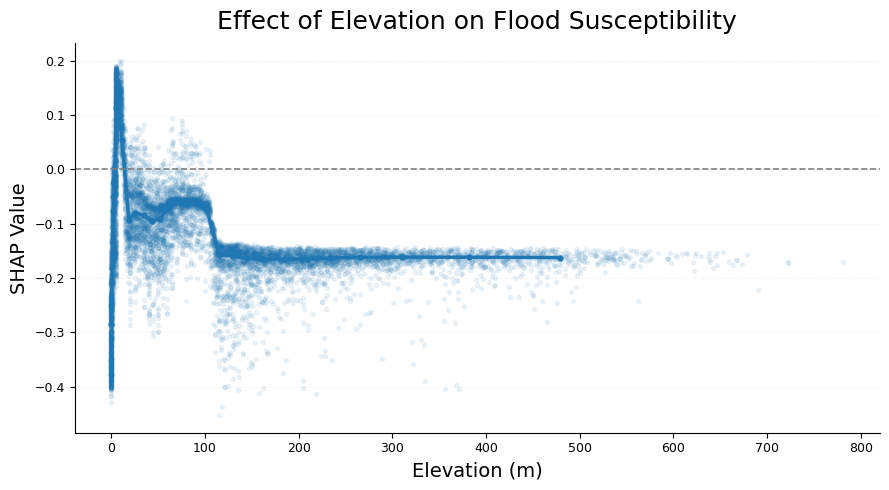

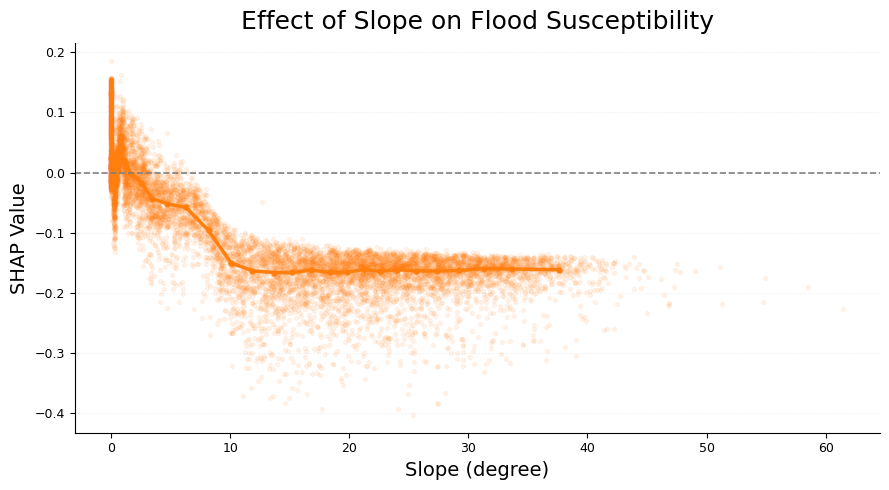

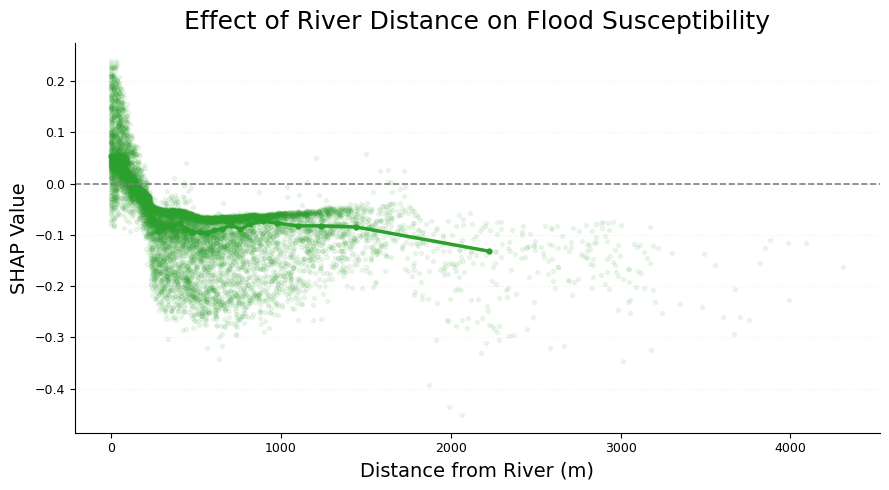

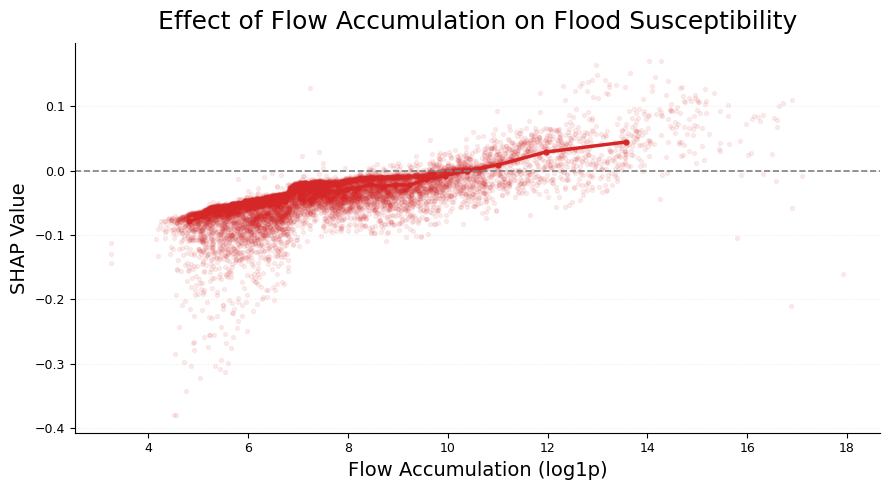

In [ ]:
import matplotlib.pyplot as plt

# Continuous-variable SHAP dependence plots
continuous_features = {

    "DEM": {
        "idx": dem_idx,
        "xlabel": "Elevation (m)",
        "title": "Effect of Elevation on Flood Susceptibility",
        "color": "tab:blue"
    },

    "Slope": {
        "idx": slope_idx,
        "xlabel": "Slope (degree)",
        "title": "Effect of Slope on Flood Susceptibility",
        "color": "tab:orange"
    },

    "RiverDistance": {
        "idx": river_idx,
        "xlabel": "Distance from River (m)",
        "title": "Effect of River Distance on Flood Susceptibility",
        "color": "tab:green"
    },

    "FA_log1p": {
        "idx": fa_idx,
        "xlabel": "Flow Accumulation (log1p)",
        "title": "Effect of Flow Accumulation on Flood Susceptibility",
        "color": "tab:red"
    }
}


for feature, info in continuous_features.items():
    plot_df = pd.DataFrame({
        "Value": X_shap_final[feature].to_numpy(),
        "SHAP": shap_class1_final[:, info["idx"]]
    })

    # 30 quantile bins
    plot_df["bin"] = pd.qcut(
        plot_df["Value"],
        q=30,
        duplicates="drop"
    )

    # Median trend
    trend = (
        plot_df
        .groupby("bin", observed=True)
        .agg(
            Value=("Value", "median"),
            SHAP=("SHAP", "median")
        )
        .reset_index(drop=True)
    )

    # Slightly smaller figure
    fig, ax = plt.subplots(figsize=(9, 5))

    # Individual SHAP samples
    ax.scatter(
        plot_df["Value"],
        plot_df["SHAP"],
        s=8,
        alpha=0.08,
        color=info["color"]
    )

    # Median SHAP trend
    ax.plot(
        trend["Value"],
        trend["SHAP"],
        linewidth=2.5,
        marker="o",
        markersize=3.5,
        color=info["color"]
    )

    # SHAP = 0
    ax.axhline(
        y=0,
        color="gray",
        linestyle="--",
        linewidth=1.2
    )

    ax.set_xlabel(
        info["xlabel"],
        fontsize=14
    )

    ax.set_ylabel(
        "SHAP Value",
        fontsize=14
    )

    ax.set_title(
        info["title"],
        fontsize=18,
        pad=10
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

### SHAP Analysis of Categorical Flood Susceptibility Factors

In [ ]:
# Select all one-hot encoded LULC columns from the SHAP samples
lulc_cols = [c for c in X_shap_final.columns if c.startswith("LULC_")]

# Recover the actual LULC code for each grid cell
lulc_actual = (
    X_shap_final[lulc_cols]
    .idxmax(axis=1) # idxmax(axis=1) returns the column name with the highest value (1) in each row
    .str.replace("LULC_", "", regex=False) # Remove the "LULC_" prefix to obtain the original LULC code
)

# Combine the actual LULC codes with their aggregated SHAP contributions
lulc_plot = pd.DataFrame({
    "LULC": lulc_actual.to_numpy(),
    "LULC_SHAP": shap_5factor_final["LULC"].to_numpy()
})

# Group grid cells by LULC category and calculate SHAP statistics
lulc_summary = (
    lulc_plot
    .groupby("LULC")
    .agg(
        n=("LULC_SHAP", "size"),                  # Number of grid cells
        Mean_SHAP=("LULC_SHAP", "mean"),          # Mean SHAP contribution
        Median_SHAP=("LULC_SHAP", "median"),      # Median SHAP contribution
        Positive_ratio=("LULC_SHAP", lambda x: (x > 0).mean())  # Proportion of positive SHAP values
    )
    .sort_values("Mean_SHAP")  # Sort by mean SHAP in ascending order
)

print(lulc_summary)

         n  Mean_SHAP  Median_SHAP  Positive_ratio
LULC                                              
152     96  -0.191263    -0.193082        0.000000
521     72  -0.163011    -0.165243        0.000000
153     39  -0.118928    -0.103374        0.025641
321   2070  -0.115960    -0.108153        0.000000
121    228  -0.112581    -0.107247        0.004386
311   1464  -0.101237    -0.096487        0.000000
421     43  -0.095480    -0.084188        0.000000
155      1  -0.084005    -0.084005        0.000000
613     43  -0.075936    -0.048463        0.000000
331    796  -0.074205    -0.069634        0.000000
623    498  -0.055426    -0.037374        0.090361
141     41  -0.054354    -0.038399        0.024390
511     82  -0.036294    -0.031673        0.219512
411     26  -0.034167    -0.041135        0.076923
611     22  -0.030768    -0.034813        0.090909
423    894  -0.030345    -0.017840        0.204698
161      9  -0.028471    -0.007819        0.222222
612      3  -0.028345    -0.060

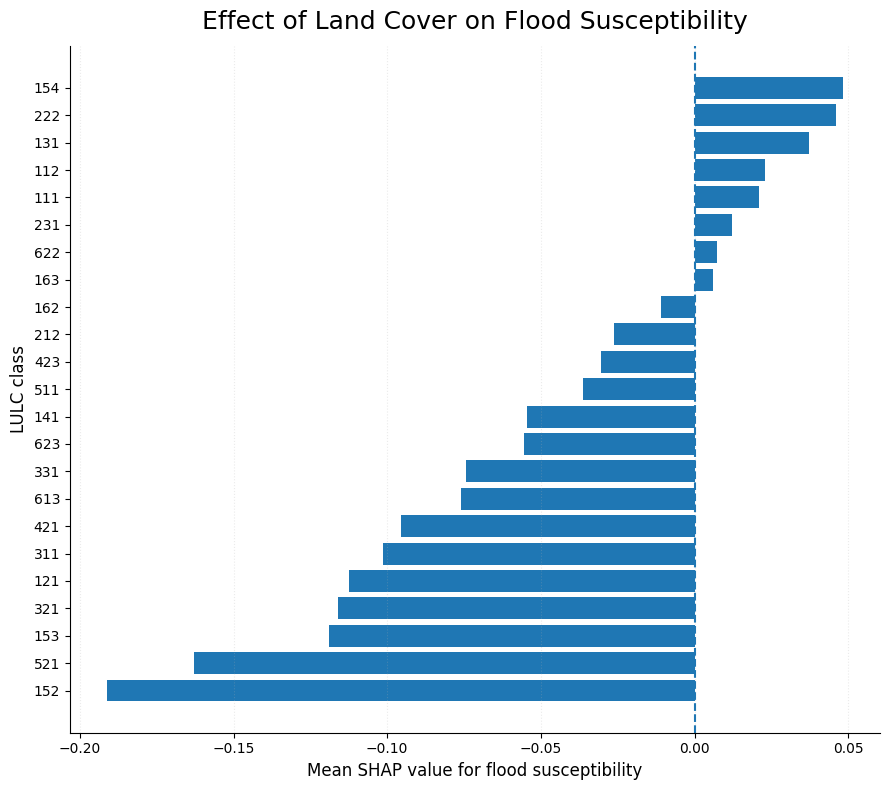

In [30]:
# Select LULC classes with at least 30 SHAP samples for clearer presentation
# Sort the selected classes by mean SHAP contribution in ascending order
lulc_bar = (
    lulc_summary[lulc_summary["n"] >= 30]
    .sort_values("Mean_SHAP")
    .copy()
)

# Create a horizontal bar chart of mean SHAP values by LULC class
fig, ax = plt.subplots(figsize=(9, 8))

ax.barh(
    lulc_bar.index.astype(str),
    lulc_bar["Mean_SHAP"]
)

# Add a reference line at SHAP = 0
ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5
)

ax.set_xlabel(
    "Mean SHAP value for flood susceptibility",
    fontsize=12
)
ax.set_ylabel("LULC class", fontsize=12)

ax.set_title(
    "Effect of Land Cover on Flood Susceptibility",
    fontsize=18,
    pad=12
)

# Add vertical grid lines to improve readability
ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.25
)

# Remove the top and right plot borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Plot LULC SHAP Contributions with Land Cover Class Names (Only Classes with n ≥ 100 in the 10,000 SHAP Samples)

In [ ]:
import geopandas as gpd

lulc_shp = r"C:\Users\nayou\OneDrive\문서\공모전\2026 부산 Big Data 활용대회\복기\LULC_merged.shp"
lulc_gdf = gpd.read_file(lulc_shp)

# Extract LULC name
lulc_code_table = (
    lulc_gdf[["L3_CODE", "L3_NAME"]]
    .drop_duplicates()
    .sort_values("L3_CODE")
    .reset_index(drop=True)
)

print(lulc_code_table.to_string(index=False))

L3_CODE     L3_NAME
    111      단독주거시설
    112      공동주거시설
    121        공업시설
    131     상업·업무시설
    141  문화·체육·휴양시설
    152          항만
    153          철도
    154          도로
    155  기타 교통·통신시설
    161      환경기초시설
    162     교육·행정시설
    163     기타 공공시설
    211   경지정리가 된 논
    212 경지정리가 안 된 논
    221   경지정리가 된 밭
    222 경지정리가 안 된 밭
    231       시설재배지
    241         과수원
    251      목장·양식장
    252       기타재배지
    311        활엽수림
    321        침엽수림
    331         혼효림
    411        자연초지
    421         골프장
    422          묘지
    423        기타초지
    511        내륙습지
    521          갯벌
    611          해변
    612         강기슭
    613       암벽·바위
    621        채광지역
    622         운동장
    623        기타나지
    711          하천
    712          호소
    721         해양수


                           LULC_name     n  Mean_SHAP  Median_SHAP  \
LULC                                                                 
321                Coniferous Forest  2070  -0.115960    -0.108153   
121                       Industrial   228  -0.112581    -0.107247   
311                 Deciduous Forest  1464  -0.101237    -0.096487   
331                     Mixed Forest   796  -0.074205    -0.069634   
623                  Other Bare Land   498  -0.055426    -0.037374   
423                  Other Grassland   894  -0.030345    -0.017840   
212    Paddy Field (Non-reorganized)   342  -0.026246    -0.034481   
231           Greenhouse Cultivation   128   0.012052    -0.009134   
111             Detached Residential   136   0.020845     0.013045   
131            Commercial & Business   235   0.037125     0.030627   
222   Upland Field (Non-reorganized)   441   0.046000     0.038310   
154                             Road  2013   0.048376     0.041764   

      Positive_rati

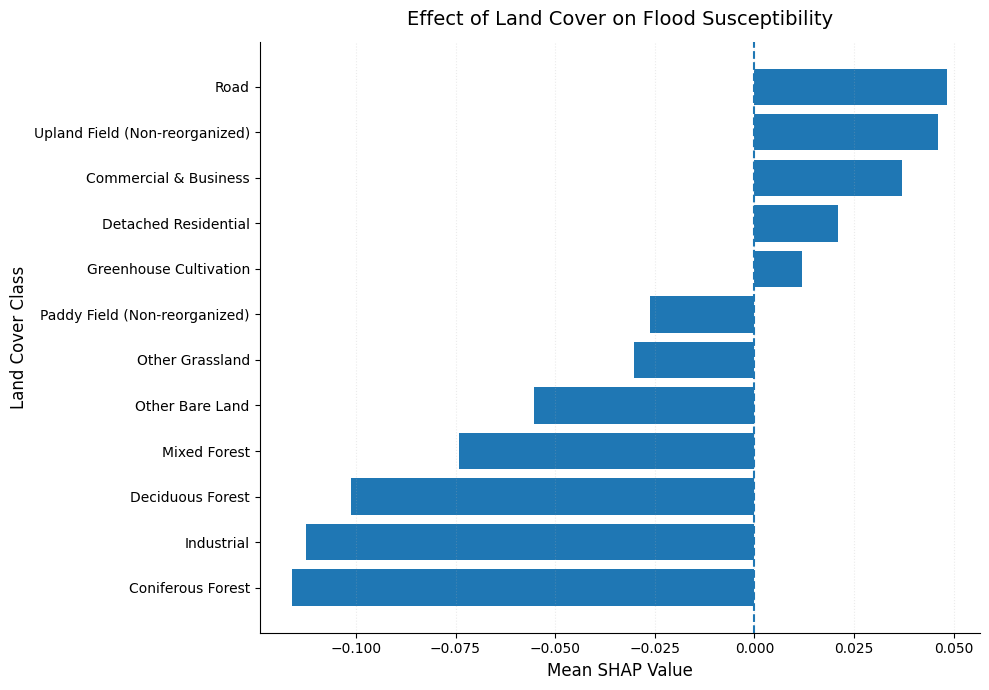

In [ ]:
# Map LULC classification codes to descriptive land cover class names
lulc_name_map = {
    "111": "Detached Residential",
    "112": "Multi-family Residential",
    "121": "Industrial",
    "131": "Commercial & Business",
    "141": "Cultural, Sports & Recreation",
    "152": "Port",
    "153": "Railway",
    "154": "Road",
    "155": "Other Transport & Communication",
    "161": "Environmental Infrastructure",
    "162": "Educational & Administrative",
    "163": "Other Public Facilities",
    "211": "Paddy Field (Reorganized)",
    "212": "Paddy Field (Non-reorganized)",
    "221": "Upland Field (Reorganized)",
    "222": "Upland Field (Non-reorganized)",
    "231": "Greenhouse Cultivation",
    "241": "Orchard",
    "251": "Ranch & Aquaculture",
    "252": "Other Cultivated Land",
    "311": "Deciduous Forest",
    "321": "Coniferous Forest",
    "331": "Mixed Forest",
    "411": "Natural Grassland",
    "421": "Golf Course",
    "422": "Cemetery",
    "423": "Other Grassland",
    "511": "Inland Wetland",
    "521": "Tidal Flat",
    "611": "Beach",
    "612": "Riverbank",
    "613": "Rock & Cliff",
    "621": "Mining Area",
    "622": "Sports Field",
    "623": "Other Bare Land",
    "711": "River",
    "712": "Lake",
    "721": "Marine Water"
}


# Select LULC classes with at least 100 samples
# Filter sufficiently represented classes and sort by mean SHAP value
lulc_bar = (
    lulc_summary[lulc_summary["n"] >= 100]
    .sort_values("Mean_SHAP")
    .copy()
)

# Replace LULC codes with descriptive class names
# Keep the original code if no matching name is found
lulc_bar["LULC_name"] = [
    lulc_name_map.get(str(code), str(code))
    for code in lulc_bar.index
]

# Display SHAP statistics for the selected LULC classes
print(
    lulc_bar[
        ["LULC_name", "n", "Mean_SHAP",
         "Median_SHAP", "Positive_ratio"]
    ]
)



# Visualize mean SHAP contributions by land cover class
# Create a horizontal bar chart using descriptive LULC names
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    lulc_bar["LULC_name"],
    lulc_bar["Mean_SHAP"]
)

# Add a reference line at SHAP = 0
ax.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5
)

# Set axis labels and chart title
ax.set_xlabel("Mean SHAP Value", fontsize=12)
ax.set_ylabel("Land Cover Class", fontsize=12)

ax.set_title(
    "Effect of Land Cover on Flood Susceptibility",
    fontsize=14,
    pad=12
)

# Add vertical grid lines for readability
ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.25
)

# Remove the top and right plot borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Top 10% Flood-Susceptible Areas Relative to Busan's Total Land Area

### Continuous Flood Susceptibility Factors

In [36]:
threshold_90 = df_map["FloodSusceptibility"].quantile(0.90)

df_map["HighRisk_Top10"] = (
    df_map["FloodSusceptibility"] >= threshold_90
)

df_top10 = df_map[df_map["HighRisk_Top10"]].copy()

print("90th percentile threshold:", threshold_90)
print("Total terrestrial cells:", len(df_map))
print("Top 10% cells:", len(df_top10))
print("Top 10% ratio:", len(df_top10) / len(df_map))

# 25m × 25m = 625 m²
top10_area_km2 = len(df_top10) * 625 / 1_000_000

print("Top 10% area (km²):", top10_area_km2)


# Continuous-variable comparison
features = [
    "DEM",
    "Slope",
    "FA_log1p",
    "RiverDistance"
]

comparison = pd.DataFrame({
    "Busan_mean": df_map[features].mean(),
    "Top10_mean": df_top10[features].mean(),
    "Busan_median": df_map[features].median(),
    "Top10_median": df_top10[features].median()
})

comparison["Mean_difference"] = (
    comparison["Top10_mean"] -
    comparison["Busan_mean"]
)

print("\nContinuous-variable comparison:")
print(comparison)

90th percentile threshold: 0.5018217464865588
Total terrestrial cells: 1204521
Top 10% cells: 120453
Top 10% ratio: 0.10000074718498059
Top 10% area (km²): 75.283125

Continuous-variable comparison:
               Busan_mean  Top10_mean  Busan_median  Top10_median  \
DEM            109.170059   17.248190     64.292633      5.000000   
Slope           13.142720    1.365850     11.247018      0.000000   
FA_log1p         7.727104    9.288643      7.310019      8.674605   
RiverDistance  550.994080  303.549835    421.070068    128.160065   

               Mean_difference  
DEM                 -91.921867  
Slope               -11.776870  
FA_log1p              1.561539  
RiverDistance      -247.444244  


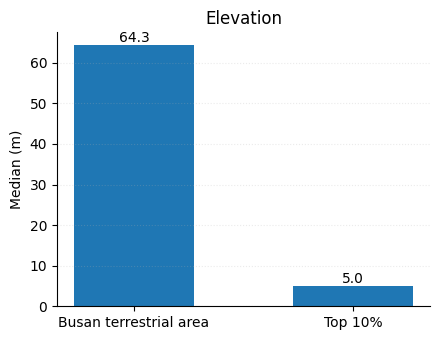

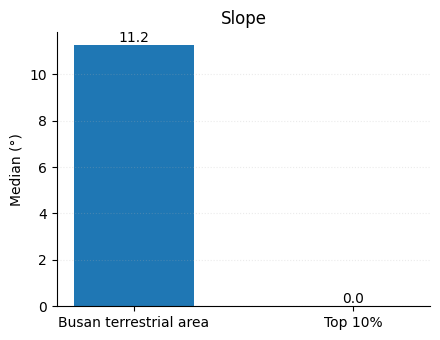

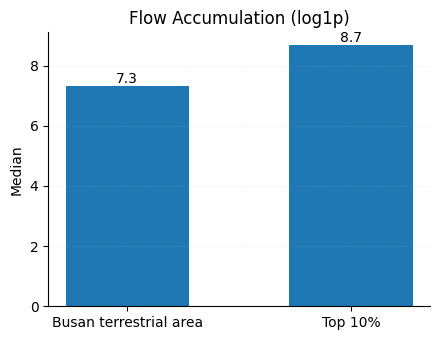

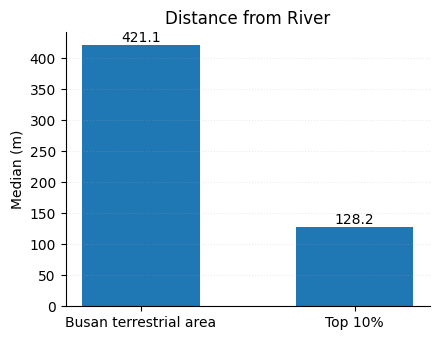

In [38]:
continuous_info = {
    "DEM": {
        "label": "Elevation",
        "unit": "m"
    },
    "Slope": {
        "label": "Slope",
        "unit": "°"
    },
    "FA_log1p": {
        "label": "Flow Accumulation (log1p)",
        "unit": ""
    },
    "RiverDistance": {
        "label": "Distance from River",
        "unit": "m"
    }
}

for feature, info in continuous_info.items():
    busan_value = df_map[feature].median()
    top10_value = df_top10[feature].median()

    fig, ax = plt.subplots(figsize=(4.5, 3.5))

    bars = ax.bar(
        ["Busan terrestrial area", "Top 10%"],
        [busan_value, top10_value],
        width=0.55
    )

    ylabel = (
        f"Median ({info['unit']})"
        if info["unit"]
        else "Median"
    )

    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(info["label"], fontsize=12)

    for bar, value in zip(bars, [busan_value, top10_value]):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [39]:
# Investigate the Zero Median Slope in the Top 10% Flood-Susceptible Areas
# Examine slope statistics in the top 10% flood-susceptible areas
print(df_top10["Slope"].describe())

# Count grid cells with a slope of exactly zero
print("\nSlope == 0:")
print((df_top10["Slope"] == 0).sum())

# Calculate the proportion of grid cells with a slope of exactly zero
print("\nSlope == 0 ratio:")
print((df_top10["Slope"] == 0).mean())

# Examine slope percentiles to understand the distribution of low slope values
print("\nSlope percentiles:")
print(
    df_top10["Slope"].quantile(
        [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
    )
)


count    120453.000000
mean          1.365850
std           2.600203
min           0.000000
25%           0.000000
50%           0.000000
75%           1.694895
max          36.607784
Name: Slope, dtype: float64

Slope == 0:
61508

Slope == 0 ratio:
0.5106390044249625

Slope percentiles:
0.00     0.000000
0.10     0.000000
0.25     0.000000
0.50     0.000000
0.75     1.694895
0.90     4.494106
1.00    36.607784
Name: Slope, dtype: float64


### Categorical Flood Susceptibility Factors (LULC)

In [42]:
# Calculate LULC proportions in the entire Busan terrestrial area
busan_ratio = df_map["LULC"].astype(str).value_counts(normalize=True)

# Calculate LULC proportions in the top 10% flood-susceptible areas
top10_ratio = df_top10["LULC"].astype(str).value_counts(normalize=True)

# Combine the two LULC distributions
lulc_comparison = pd.DataFrame({
    "Busan_ratio": busan_ratio,
    "Top10_ratio": top10_ratio
}).fillna(0)

# Calculate the relative representation of each LULC class
lulc_comparison["Representation_ratio"] = (
    lulc_comparison["Top10_ratio"] /
    lulc_comparison["Busan_ratio"].replace(0, np.nan)
)

print(lulc_comparison)

       Busan_ratio  Top10_ratio  Representation_ratio
LULC                                                 
111.0     0.013590     0.019850              1.460588
112.0     0.010340     0.025520              2.468067
121.0     0.020613     0.012594              0.610975
131.0     0.022229     0.066134              2.975141
141.0     0.004590     0.006351              1.383603
152.0     0.010423     0.000556              0.053365
153.0     0.003773     0.002374              0.629258
154.0     0.198065     0.447668              2.260204
155.0     0.000117     0.000706              6.028324
161.0     0.000565     0.000598              1.058816
162.0     0.004467     0.006799              1.522011
163.0     0.003426     0.008186              2.389127
211.0     0.000302     0.002059              6.813136
212.0     0.035166     0.038563              1.096597
221.0     0.000268     0.001669              6.222864
222.0     0.046990     0.113588              2.417296
231.0     0.012929     0.018

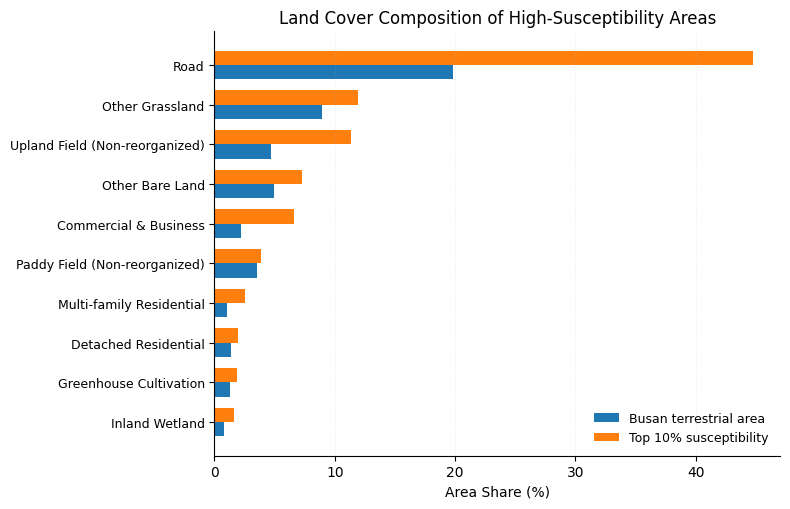

                            LandCover  Busan_pct  Top10_pct  \
LULC                                                          
154.0                            Road      19.81      44.77   
423.0                 Other Grassland       8.98      11.92   
222.0  Upland Field (Non-reorganized)       4.70      11.36   
623.0                 Other Bare Land       4.97       7.24   
131.0           Commercial & Business       2.22       6.61   
212.0   Paddy Field (Non-reorganized)       3.52       3.86   
112.0        Multi-family Residential       1.03       2.55   
111.0            Detached Residential       1.36       1.99   
231.0          Greenhouse Cultivation       1.29       1.90   
511.0                  Inland Wetland       0.80       1.59   

       Representation_ratio  
LULC                         
154.0                  2.26  
423.0                  1.33  
222.0                  2.42  
623.0                  1.46  
131.0                  2.98  
212.0                  1.10  
112

In [45]:
# Create a copy of the LULC comparison DataFrame
lulc_plot = lulc_comparison.copy()

# Convert float LULC codes to integer strings and map them to English class names
lulc_plot["LandCover"] = [
    lulc_name_map.get(str(int(float(code))), str(code))
    for code in lulc_plot.index
]

# Select the 10 most common LULC classes in the top 10% flood-susceptible areas
lulc_plot = (
    lulc_plot
    .sort_values("Top10_ratio", ascending=False)
    .head(10)
    .copy()
)

# Convert land cover proportions to percentages
lulc_plot["Busan_pct"] = lulc_plot["Busan_ratio"] * 100
lulc_plot["Top10_pct"] = lulc_plot["Top10_ratio"] * 100

# Sort by Top 10% area share so that the largest values appear at the top
lulc_plot = lulc_plot.sort_values("Top10_pct", ascending=True)



# Visualize land cover composition using grouped horizontal bars
fig, ax = plt.subplots(figsize=(8, 5.2))

# Define y-axis positions and bar height
y = np.arange(len(lulc_plot))
h = 0.36

# Plot land cover percentages for the entire Busan terrestrial area
ax.barh(
    y - h/2,
    lulc_plot["Busan_pct"],
    height=h,
    label="Busan terrestrial area"
)

# Plot land cover percentages for the top 10% flood-susceptible areas
ax.barh(
    y + h/2,
    lulc_plot["Top10_pct"],
    height=h,
    label="Top 10% susceptibility"
)

# Set y-axis positions and land cover class labels
ax.set_yticks(y)
ax.set_yticklabels(
    lulc_plot["LandCover"],
    fontsize=9
)

ax.set_xlabel("Area Share (%)", fontsize=10)

ax.set_title(
    "Land Cover Composition of High-Susceptibility Areas",
    fontsize=12
)

# Add a legend without a surrounding frame
ax.legend(
    frameon=False,
    fontsize=9
)

# Add vertical grid lines for readability
ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.25
)

# Remove the top and right plot borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



# Display the comparison table with descriptive land cover names
# Select columns for the final summary table
display_cols = [
    "LandCover",
    "Busan_pct",
    "Top10_pct",
    "Representation_ratio"
]

# Display the results sorted by Top 10% area share, rounded to two decimal places
print(
    lulc_plot[display_cols]
    .sort_values("Top10_pct", ascending=False)
    .round(2)
)